# エンコーディング切り替えFMQAによるブラックボックス最適化

小川 涼，関 優也

[Ogawa, Ryo, et al. "Stage-dependent integer-binary encoding in factorization-machine black-box optimization." arXiv preprint arXiv:2606.23188 (2026)](https://arxiv.org/abs/2606.23188)

[arXiv版論文リンク](https://arxiv.org/abs/2606.23188)

## エンコーディング切り替えFMQAの概要
- エンコーディング切り替えFMQAは，ブラックボックス最適化手法であるfactorization machine with quadratic-optimization annealing (FMQA)[1]の拡張手法として提案された．
- FMによるサロゲートモデルの学習段階とイジングマシンによる解探索段階で異なる整数・バイナリエンコーディングを用いることで，各段階に適したエンコーディングを選択可能にし，FMQAの最適化性能の向上を図る．

[1] [K. Kitai et al., Phys. Rev. Res., 2, 013319 (2020).](https://journals.aps.org/prresearch/abstract/10.1103/PhysRevResearch.2.013319) \

## 背景

* FMQAでは，連続変数や整数変数を扱うため，one-hot，domain-wall，binaryなどの整数・バイナリエンコーディングが用いられる．
* 一方，先行研究では，イジングマシンによる解探索ではdomain-wallエンコーディングが優れた性能を示すことが報告されている[1]–[3]．また，FMQA全体ではone-hotエンコーディングが優れた最適化性能を示すことが報告されている[4]．

FMQAでは，FMによって学習されたサロゲートモデルがQUBOとして表現され，その後イジングマシンによって最適化される．QUBOは次式で表される．

$$
H(\boldsymbol{x})
=
\boldsymbol{x}
Q
\boldsymbol{x}^{\top}.
$$

* $H(\boldsymbol{x})$：QUBOエネルギー
* $\boldsymbol{x}$：バイナリ変数ベクトル
* $Q$：FMから構築されたQUBO行列

従来のFMQAでは，FMの学習段階とイジングマシンによる解探索段階で，同一の整数・バイナリエンコーディングを用いる．しかし，学習段階ではFMの近似精度が重要である一方，解探索段階ではイジングマシンによる低エネルギー解探索性能が重要となる．そのため，同一のエンコーディングを両段階で用いることにより，各段階の性能を個別に最適化できず，FMQA全体の最適化性能が制限される可能性がある．

### 参考文献

[1] S. Kikuchi, K. Takahashi, and S. Tanaka, *Performance of Domain-Wall encoding in a digital Ising machine*, arXiv:2410.11198 (2024).

[2] J. Chen, T. Stollenwerk, and N. Chancellor, *Performance of Domain-Wall encoding for quantum annealing*, IEEE Transactions on Quantum Engineering **2**, 1 (2021).

[3] K. Tamura, T. Shirai, H. Katsura, S. Tanaka, and N. Togawa, *Performance comparison of typical binary-integer encodings in an Ising machine*, IEEE Access **9**, 81032 (2021).

[4] Y. Seki, R. Tamura, and S. Tanaka, *Black-box optimization for integer-variable problems using Ising machines and factorization machines*, arXiv:2209.01016 (2022).

## 手法の目的

FMによるサロゲートモデルの学習段階とイジングマシンによる解探索段階で，それぞれの段階に適した整数・バイナリエンコーディングを用いることで，FMQAの最適化性能の向上を図ること．本Notebookでは，学習段階にone-hotエンコーディング，解探索段階にdomain-wallエンコーディングを用いる．

## エンコーディング切り替えFMQAの手順

### 入力（パラメータ名）

* $f$ (`bb_func`): 最適化対象のブラックボックス関数
* $N$ (`N`): 入力変数の次元数
* $q$ (`q`): 各連続変数の離散化点数
* $N_{\mathrm{iter}}$ (`n_iter`): FMQAの反復回数
* $D_{\mathrm{init}}$ (`n_init_data`): 初期学習データ数
* $K$ (`K`): Factorization Machine (FM) のランク
* $\mu$ (`penalty`): エンコーディング制約に対するペナルティ係数

### 出力（属性名）

* $\boldsymbol{u}_{\mathrm{best}}$ (`result.best.values`): 最良の連続変数
* $f(\boldsymbol{u}_{\mathrm{best}})$ (`result.best.objective`): ブラックボックス関数値

### アルゴリズムの手順

#### 初期学習データセットの構築

* $D_{\mathrm{init}}$ 個の連続変数
  $\boldsymbol{u}^{(d)} \in [u_{\min},u_{\max}]^N$
  を生成する．
* 各入力についてブラックボックス関数を評価する．

$$
y^{(d)} = f(\boldsymbol{u}^{(d)}).
$$

* 初期学習データセット

$$
\mathcal{D}^{(0)}
=
\{
(\boldsymbol{u}^{(1)},y^{(1)}),
\dots,
(\boldsymbol{u}^{(D_{\mathrm{init}})},y^{(D_{\mathrm{init}})})
\}
$$

を構築する．

#### 最適化ループ（$t=1,\ldots,N_{\mathrm{iter}}$）

* **Step 1: FMによる学習**

  * 各連続変数を離散化し，学習段階で用いる整数・バイナリエンコーディング（one-hotまたはdomain-wall）へ変換する．
  * データセット $\mathcal{D}^{(t-1)}$ を用いてFMを学習し，サロゲートモデルを構築する．
  * 学習済みFMからQUBO行列を生成する．

* **Step 2: QUBO行列の変換**

  * 学習段階と解探索段階で異なるエンコーディングを用いる場合，QUBO行列を対応するエンコーディングへ変換する．
  * エンコーディング制約項は変換せず，解探索段階で用いるエンコーディングに対応する制約項を新たに付加する．

* **Step 3: イジングマシンによる解探索**

  * 構築したQUBOをイジングマシンへ入力し，

$$
H
=
f_{\mathrm{FM}}
+
\mu f_{\mathrm{const}}
$$

を最小化する解を探索する．

  * 得られたバイナリ解をデコードし，連続変数

$$
\boldsymbol{u}^{*}
$$

へ変換する．

* **Step 4: BB関数の評価**

  * 得られた連続変数についてブラックボックス関数を評価する．

$$
y^{*}=f(\boldsymbol{u}^{*}).
$$

* **Step 5: 学習データセットの更新**

  * 新たな入出力対

$$
(\boldsymbol{u}^{*},y^{*})
$$

をデータセットへ追加する．
  * エンコーディング制約を満たさない解が得られた場合は破棄し，ランダムに生成した実行可能解で置き換える．

#### 最良解の出力

* 探索中に得られた解のうち，ブラックボックス関数値が最も小さい

$$
\boldsymbol{u}_{\mathrm{best}}
$$

および

$$
f(\boldsymbol{u}_{\mathrm{best}})
$$

を返す．

## ライブラリの使用方法

このライブラリでは，エンコーディング切り替えFMQAの実行に`amplify_bbopt`を使用する．

- `amplify_bbopt` のドキュメントは[こちら](https://amplify.fixstars.com/ja/docs/amplify-bbopt/v1/index.html)
- `amplify`のドキュメントは[こちら](https://amplify.fixstars.com/ja/docs/amplify/v1/index.html)

### 計算環境の準備

[Fixstars Amplify AEの利用方法](https://g-quat-abciq.github.io/abciq-docs/ja/apps/amplify-ae/)を参照して，必要ライブラリをインストールするための仮想環境を作成する．そして，仮想環境内に`amplify`と`amplify-bbopt`をインストールする．

```bash
python3 -m pip install -U amplify amplify-bbopt
```

また，`amplify-bbopt-ext`ライブラリを追加する．

```bash
python3 -m pip install git+https://github.com/Shu-Tanaka-Group/amplify-bbopt-ext.git
```

### 必要ライブラリの読み込み

In [1]:
import amplify_bbopt
import torch
from amplify import AmplifyAEClient
from amplify_bbopt_ext.qubo_conversion import generate_initial_samples, run

from datetime import timedelta
import numpy as np

In [2]:
amplify_bbopt.__version__

'1.2.0'

### ブラックボックス関数の設定

本実験では，ブラックボックス関数のベンチマークとして **Rastrigin関数** を用いる．\
Rastrigin関数は，多数の局所最適解を持つ代表的な多峰性ベンチマーク関数であり，ブラックボックス最適化アルゴリズムの性能評価に広く用いられている．

$N$次元連続変数ベクトル $\boldsymbol{u}=(u_1,\dots,u_N)$ に対し，Rastrigin関数は以下のように定義される．

$$
f(\boldsymbol{u})
=
10N
+
\sum_{i=1}^{N}
\left(
u_i^2
-
10\cos(2\pi u_i)
\right)
$$

**`N`の値は大きいほど最適解探索は困難になる．**

本実験では，各連続変数の探索範囲を

$$
-3 \le u_i \le 3
$$

とし，この区間を `q` 個の離散点に分割して最適化を行う．\
離散化された連続変数は，one-hot，domain-wall，またはbinaryエンコーディングによってバイナリ変数へ変換される．:contentReference[oaicite:0]{index=0}

Rastrigin関数の大域最適解は

$$
\boldsymbol{u}=(0,\dots,0)
$$

であり，そのとき目的関数値は

$$
f(\boldsymbol{u})=0
$$

となる．

したがって，本実験では以下の最小化問題を解く．

$$
\mathrm{minimize}\ f(\boldsymbol{u})
$$

In [3]:
import math

N = 2  # 入力次元
A = 10.0

def bb_func(u):
    return A * N + sum(
        x * x - A * math.cos(2.0 * math.pi * x)
        for x in u
    )

### パラメータの設定

### Fixstars Amplify Annealing Engineの設定

In [8]:
from datetime import timedelta
from getpass import getpass
from amplify import AmplifyAEClient

client = AmplifyAEClient()
client.token = getpass("Amplify API token: ")
client.parameters.time_limit_ms = timedelta(seconds=1)
client.parameters.num_gpus = 1

print(type(client))
print(client.url)
print(client.version)

<class 'amplify.AmplifyAEClient'>
https://optigan.fixstars.com
1.2.1+Hopper


In [9]:
# =====================================
# Problem settings
# =====================================

N = 5                  # 入力変数の次元数
q = 61                 # 各変数の離散化点数
L = -3.0               # 離散化範囲の下限
M = 3.0                # 離散化範囲の上限
encoding = "OhDw"      # {"Oh", "Dw", "Bi", "OhDw", "DwOh"}


# =====================================
# Initial dataset
# =====================================

n_init_data = 64       # 初期学習データ数 D_init
seed = 0              # 初期データ生成用シード（Noneで毎回ランダム）


# =====================================
# FMQA settings
# =====================================

K = 8                  # FMのランク
n_iter = 200


# =====================================
# FM learning settings
# =====================================

epochs = 1000

optimizer_params = {
    "lr": 0.01,         # 学習率
}

# 200エポックごとに学習率を0.9倍
lr_scheduler_class = torch.optim.lr_scheduler.StepLR
lr_scheduler_params = {
    "step_size": 200,
    "gamma": 0.9,
}

## パラメータ設定のTips

- `N`: ブラックボックス関数へ入力する実数変数の次元数を表す．
  - `N` が大きいほど探索空間が広がり，FMの入力変数とアニーリングに必要なバイナリ変数も増加する．

- `q`: 各実数変数を $[L, M]$ の範囲で離散化するときの点数を表す．
  - 離散化幅は $(M-L)/(q-1)$ である．`q` が大きいほど細かな解を表現できる一方，FMの入力次元とアニーリングの計算量が増加する．
  - One-hot表現では1変数あたり `q` ビット，Domain-wall表現では `q-1` ビット，二進表現では $\lceil\log_2 q\rceil$ ビットを使用する．
  - まず小さな `q` で挙動を確認し，必要な解像度に応じて増やすとよい．

- `L`, `M`: 各実数変数の探索範囲の下限と上限を表す．
  - 真の最適解を含む範囲を設定する必要がある．範囲を不必要に広げると，同じ `q` でも離散化が粗くなる．

- `encoding`: FMの学習とアニーリングに用いるエンコーディング方式を表す．
  - `Oh`: One-hot表現で学習・探索する．
  - `Dw`: Domain-wall表現で学習・探索する．
  - `Bi`: 二進表現で学習・探索する．
  - `OhDw`: One-hot表現で学習し，Domain-wall表現へ変換して探索する．
  - `DwOh`: Domain-wall表現で学習し，One-hot表現へ変換して探索する．
  - 問題によって有効な方式が異なるため，下部の比較実験を用いて同じ初期データと乱数シードで比較する．

- `n_init_data`: FMの初期学習に用いるデータ数 $D_{\mathrm{init}}$ を表す．
  - 大きいほど初期FMが探索空間を捉えやすくなる一方，最適化開始前のブラックボックス関数評価回数と学習時間が増加する．
  - まずは $1 \leq$ `n_init_data` $\leq 100$ 程度を目安とし，入力次元や目的関数の複雑さに応じて調整する．

- `K`: FMの交互作用を表現する潜在因子の次元数を表す．
  - 大きくすると複雑な変数間相互作用を表現できる一方，過学習や計算量増大につながる．
  - $8 \leq$ `K` $\leq 10$ 程度を初期値の目安とし，検証結果に応じて調整する．

- `n_iter`: FMQAの最適化サイクルの総反復回数を表す．
  - 1反復ごとにFMの再学習，アニーリング，ブラックボックス関数の評価が行われる．
  - 大きいほど探索機会が増えるが，実行時間とブラックボックス関数の評価回数も増加する．まず小規模な値で動作確認し，収束曲線が改善し続けている場合に増やす．

- `epochs`: 各FMQA反復におけるFM学習の勾配更新回数を表す．
  - 大きいほど各反復の学習時間が増加する．
  - `n_iter` を十分に確保できる場合は `epochs=1000` を出発点とし，学習の収束が不十分な場合は `epochs=2000` 程度へ増やす．

- `optimizer_params["lr"]`: FM学習時の学習率を表す．
  - 大きすぎると損失が不安定になり，小さすぎると限られた `epochs` 内で収束しにくい．
  - `lr=0.01` を一般的な出発点とし，損失の推移と使用するオプティマイザに応じて調整する．

- `lr_scheduler_class`, `lr_scheduler_params`: FM学習中の学習率スケジュールを表す．
  - この例の `StepLR` は `step_size` エポックごとに学習率を `gamma` 倍する．
  - 学習後半の振動を抑えたい場合に有効だが，学習率が早く下がりすぎると収束が遅くなる．

### 初期データ生成

- 初期学習データのための解を生成する．
- 初期学習データ数 `n_init_data` は，エンコーディング切り替えFMQAの最適化性能に大きく影響しない．
- ただし，`n_init_data` はブラックボックス関数の評価回数に相当するため，大きすぎる `n_init_data` の設定はコストの増大につながる．
    - $1 \leq$ `n_init_data` $\leq 100$ 程度で問題ない．

In [10]:
X_real, initial_samples = generate_initial_samples(
    N=N,
    L=L,
    M=M,
    q=q,
    n_samples=n_init_data,
    encoding=encoding,
    seed=seed,
)

### FMQAの実行

In [ ]:
result = run(
    client=client,
    bb_func=bb_func,
    N=N,
    q=q,
    L=L,
    M=M,
    encoding=encoding,
    k=K,
    n_iter=n_iter,
    initial_data=initial_samples,
    epochs=epochs,
    optimizer_params=optimizer_params,
    lr_scheduler_class=lr_scheduler_class,
    lr_scheduler_params=lr_scheduler_params,
    seed=seed,
)

print(result.best.values)      # ベスト解（入力値）
print(result.best.objective)   # ベスト解に対応する目的関数値

[2026-08-19 15:34:57] [amplify_bbopt] [INFO] === Iteration: 1/200 ===
[2026-08-19 15:34:57] [amplify_bbopt] [INFO] training error: 3.047e-03
[2026-08-19 15:34:57] [amplify_bbopt] [INFO] Converting QUBO encoding: Oh -> Dw (N=5, q=61)
[2026-08-19 15:34:58] [amplify_bbopt] [INFO] QUBO conversion verification passed: Oh -> Dw, states=256
[2026-08-19 15:34:59] [amplify_bbopt] [INFO]    objective: 7.331e+01
[2026-08-19 15:34:59] [amplify_bbopt] [INFO] current best: 2.971e+01
[2026-08-19 15:34:59] [amplify_bbopt] [INFO] === Iteration: 2/200 ===
[2026-08-19 15:34:59] [amplify_bbopt] [INFO] training error: 2.957e-03
[2026-08-19 15:34:59] [amplify_bbopt] [INFO] Converting QUBO encoding: Oh -> Dw (N=5, q=61)
[2026-08-19 15:34:59] [amplify_bbopt] [INFO] QUBO conversion verification passed: Oh -> Dw, states=256
[2026-08-19 15:35:01] [amplify_bbopt] [INFO]    objective: 6.575e+01
[2026-08-19 15:35:01] [amplify_bbopt] [INFO] current best: 2.971e+01
[2026-08-19 15:35:01] [amplify_bbopt] [INFO] === Ite

## 結果の可視化

左図はFMQAの反復に対する目的関数値の推移を示す．

- 青色: 初期学習データ
- 灰色: 各反復で学習データへ追加された解
- 赤色: 各反復でアニーリングから直接得られたベスト解
- 黒色: その反復までに得られた目的関数値の最小値

右図は，2変数問題の場合に探索点を目的関数値で色付けして表示する．

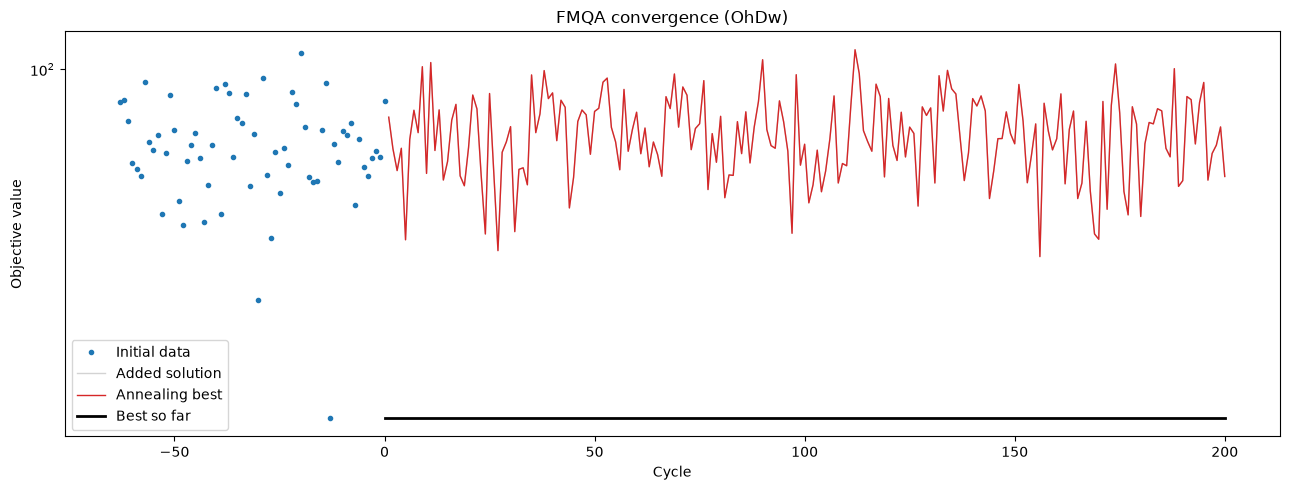

In [ ]:
import matplotlib.pyplot as plt

# 初期学習データの目的関数値
objectives_init = np.asarray([bb_func(x) for x in X_real], dtype=float)

# 各反復でアニーリングから直接得られたベスト解
objectives_annealing_best = np.asarray([
    float(h.annealing_best_solution.objective) for h in result.history
])

# 各反復で実際に学習データへ追加された解
added_solutions = [
    h.annealing_new_solution
    if h.annealing_new_solution is not None
    else h.fallback_solution
    for h in result.history
]
objectives_added = np.asarray([
    float(solution.objective) for solution in added_solutions
])

# 初期データを含む、その時点までの最良値
best_so_far = np.minimum.accumulate(
    np.concatenate(([objectives_init.min()], objectives_added))
)

fig, axes = plt.subplots(1, 2 if N == 2 else 1, figsize=(13, 5))
if N != 2:
    axes = [axes]

ax = axes[0]
ax.plot(range(-n_init_data + 1, 1), objectives_init, "o", color="tab:blue", markersize=3, label="Initial data")
ax.plot(range(1, len(objectives_added) + 1), objectives_added, color="lightgrey", linewidth=1, label="Added solution")
ax.plot(range(1, len(objectives_annealing_best) + 1), objectives_annealing_best, color="tab:red", linewidth=1, label="Annealing best")
ax.plot(range(0, len(best_so_far)), best_so_far, color="black", linewidth=2, label="Best so far")
ax.set_xlabel("Cycle")
ax.set_ylabel("Objective value")
ax.set_yscale("symlog", linthresh=1e-3)
ax.set_title(f"FMQA convergence ({encoding})")
ax.legend()

if N == 2:
    iteration_points = np.asarray([
        next(iter(solution.values.values())) for solution in added_solutions
    ], dtype=float)
    all_points = np.vstack((X_real, iteration_points))
    all_objectives = np.concatenate((objectives_init, objectives_added))
    best_point = all_points[np.argmin(all_objectives)]

    scatter = axes[1].scatter(
        all_points[:, 0], all_points[:, 1],
        c=all_objectives, cmap="viridis", s=18, alpha=0.75,
    )
    axes[1].scatter(
        best_point[0], best_point[1], marker="*", s=220,
        color="red", edgecolor="black", label="Best solution",
    )
    axes[1].set_xlim(L, M)
    axes[1].set_ylim(L, M)
    axes[1].set_xlabel("$u_1$")
    axes[1].set_ylabel("$u_2$")
    axes[1].set_title("Search points")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()
    fig.colorbar(scatter, ax=axes[1], label="Objective value")

plt.tight_layout()
plt.show()

## エンコーディング手法の比較

同一の初期データを用いて，複数のエンコーディング手法の収束性能と探索点を比較する．

- すべての手法に同じ実数初期点 `X_real` を与える．
- 左図では，初期データを含む各反復までの最良目的関数値を比較する．
- 2変数問題の場合，右側に手法ごとの探索点を並べて表示する．

In [ ]:
comparison_encodings = ["Oh", "Dw", "Bi", "OhDw", "DwOh"]

# 全手法で共通の初期点と目的関数値を使用する
comparison_X_real = np.asarray(X_real, dtype=float).copy()
comparison_objectives_init = np.asarray(
    [bb_func(x) for x in comparison_X_real], dtype=float
)

comparison_results = {}
comparison_data = {}

for comparison_encoding in comparison_encodings:
    print(f"Running {comparison_encoding}...")
    comparison_result = run(
        client=client,
        bb_func=bb_func,
        N=N,
        q=q,
        L=L,
        M=M,
        encoding=comparison_encoding,
        k=K,
        n_iter=n_iter,
        initial_data=comparison_X_real,
        epochs=epochs,
        optimizer_params=optimizer_params,
        lr_scheduler_class=lr_scheduler_class,
        lr_scheduler_params=lr_scheduler_params,
        seed=seed,
    )
    comparison_results[comparison_encoding] = comparison_result

    added_solutions = [
        history.annealing_new_solution
        if history.annealing_new_solution is not None
        else history.fallback_solution
        for history in comparison_result.history
    ]
    added_objectives = np.asarray(
        [float(solution.objective) for solution in added_solutions],
        dtype=float,
    )
    added_points = np.asarray([
        next(iter(solution.values.values())) for solution in added_solutions
    ], dtype=float)
    best_so_far = np.minimum.accumulate(
        np.concatenate(([comparison_objectives_init.min()], added_objectives))
    )
    comparison_data[comparison_encoding] = {
        "added_points": added_points,
        "added_objectives": added_objectives,
        "best_so_far": best_so_far,
    }

# Display the final results as a table.
print("\nFinal results")
print(f"{'Method':<8} {'Best objective':>18}  Best input")
print("-" * 70)
for comparison_encoding in comparison_encodings:
    comparison_result = comparison_results[comparison_encoding]
    best_values = np.asarray(
        next(iter(comparison_result.best.values.values())), dtype=float
    )
    print(
        f"{comparison_encoding:<8} "
        f"{float(comparison_result.best.objective):>18.8g}  "
        f"{np.array2string(best_values, precision=6)}"
    )

[2026-08-19 15:03:18] [amplify_bbopt] [INFO] === Iteration: 1/200 ===


Running Oh...


[2026-08-19 15:03:18] [amplify_bbopt] [INFO] training error: 2.999e-03
2026-08-19 15:03:19 [amplify:WARNING] the time limit should be greater than specified because it was reached before the solutions converged even once.
[2026-08-19 15:03:19] [amplify_bbopt] [INFO]    objective: 3.380e+01
[2026-08-19 15:03:19] [amplify_bbopt] [INFO] current best: 1.152e+01
[2026-08-19 15:03:19] [amplify_bbopt] [INFO] === Iteration: 2/200 ===
[2026-08-19 15:03:19] [amplify_bbopt] [INFO] training error: 2.543e-03
2026-08-19 15:03:20 [amplify:WARNING] the time limit should be greater than specified because it was reached before the solutions converged even once.
[2026-08-19 15:03:20] [amplify_bbopt] [INFO]    objective: 8.865e+01
[2026-08-19 15:03:20] [amplify_bbopt] [INFO] current best: 1.152e+01
[2026-08-19 15:03:20] [amplify_bbopt] [INFO] === Iteration: 3/200 ===
[2026-08-19 15:03:20] [amplify_bbopt] [INFO] training error: 2.511e-03
2026-08-19 15:03:20 [amplify:WARNING] the time limit should be greate

Running Dw...


[2026-08-19 15:06:17] [amplify_bbopt] [INFO] training error: 8.773e-04
2026-08-19 15:06:18 [amplify:WARNING] the time limit should be greater than specified because it was reached before the solutions converged even once.
[2026-08-19 15:06:18] [amplify_bbopt] [INFO]    objective: 8.160e+01
[2026-08-19 15:06:18] [amplify_bbopt] [INFO] current best: 1.152e+01
[2026-08-19 15:06:18] [amplify_bbopt] [INFO] === Iteration: 2/200 ===
[2026-08-19 15:06:18] [amplify_bbopt] [INFO] training error: 4.640e-03
2026-08-19 15:06:18 [amplify:WARNING] the time limit should be greater than specified because it was reached before the solutions converged even once.
[2026-08-19 15:06:18] [amplify_bbopt] [INFO]    objective: 6.310e+01
[2026-08-19 15:06:18] [amplify_bbopt] [INFO] current best: 1.152e+01
[2026-08-19 15:06:18] [amplify_bbopt] [INFO] === Iteration: 3/200 ===
[2026-08-19 15:06:19] [amplify_bbopt] [INFO] training error: 5.436e-01
2026-08-19 15:06:19 [amplify:WARNING] the time limit should be greate

...

Running OhDw...


[2026-08-19 15:11:27] [amplify_bbopt] [INFO] training error: 2.521e-03
[2026-08-19 15:11:27] [amplify_bbopt] [INFO] Converting QUBO encoding: Oh -> Dw (N=5, q=61)
[2026-08-19 15:11:28] [amplify_bbopt] [INFO] QUBO conversion verification passed: Oh -> Dw, states=256
2026-08-19 15:11:28 [amplify:WARNING] the time limit should be greater than specified because it was reached before the solutions converged even once.
[2026-08-19 15:11:28] [amplify_bbopt] [INFO]    objective: 8.405e+01
[2026-08-19 15:11:28] [amplify_bbopt] [INFO] current best: 1.152e+01
[2026-08-19 15:11:28] [amplify_bbopt] [INFO] === Iteration: 2/200 ===
[2026-08-19 15:11:28] [amplify_bbopt] [INFO] training error: 2.634e-03
[2026-08-19 15:11:28] [amplify_bbopt] [INFO] Converting QUBO encoding: Oh -> Dw (N=5, q=61)
[2026-08-19 15:11:28] [amplify_bbopt] [INFO] QUBO conversion verification passed: Oh -> Dw, states=256
2026-08-19 15:11:29 [amplify:WARNING] the time limit should be greater than specified because it was reached 

Running DwOh...


[2026-08-19 15:14:45] [amplify_bbopt] [INFO] training error: 3.775e-02
[2026-08-19 15:14:45] [amplify_bbopt] [INFO] Converting QUBO encoding: Dw -> Oh (N=5, q=61)
[2026-08-19 15:14:46] [amplify_bbopt] [INFO] QUBO conversion verification passed: Dw -> Oh, states=256
2026-08-19 15:14:46 [amplify:WARNING] the time limit should be greater than specified because it was reached before the solutions converged even once.
[2026-08-19 15:14:46] [amplify_bbopt] [INFO]    objective: 5.862e+01
[2026-08-19 15:14:46] [amplify_bbopt] [INFO] current best: 1.152e+01
[2026-08-19 15:14:46] [amplify_bbopt] [INFO] === Iteration: 2/200 ===
[2026-08-19 15:14:47] [amplify_bbopt] [INFO] training error: 1.735e-02
[2026-08-19 15:14:47] [amplify_bbopt] [INFO] Converting QUBO encoding: Dw -> Oh (N=5, q=61)
[2026-08-19 15:14:47] [amplify_bbopt] [INFO] QUBO conversion verification passed: Dw -> Oh, states=256
2026-08-19 15:14:48 [amplify:WARNING] the time limit should be greater than specified because it was reached 


Final results
Method       Best objective  Best input
----------------------------------------------------------------------
Oh                 11.51983  [-2.   0.  -1.9 -1.   1. ]
Dw                 11.51983  [-2.   0.  -1.9 -1.   1. ]
Bi                 11.51983  [0. 1. 0. 1. 0. 0. 0. 1. 1. 1. 1. 0. 1. 1. 0. 1. 0. 0. 0. 0. 1. 0. 1. 0.
 0. 0. 0. 1. 0. 1.]
OhDw               11.51983  [-2.   0.  -1.9 -1.   1. ]
DwOh               11.51983  [-2.   0.  -1.9 -1.   1. ]


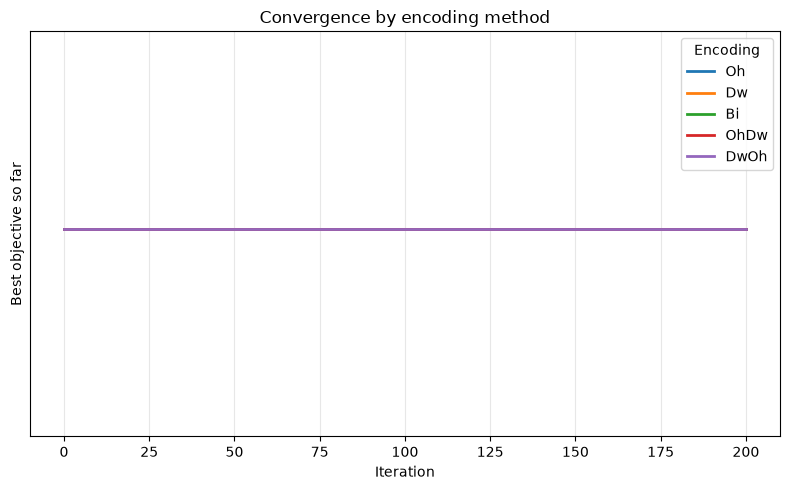

In [ ]:
# Compare convergence curves.
fig, ax = plt.subplots(figsize=(8, 5))
for comparison_encoding in comparison_encodings:
    best_so_far = comparison_data[comparison_encoding]["best_so_far"]
    ax.plot(
        range(len(best_so_far)), best_so_far, linewidth=2,
        label=comparison_encoding,
    )
ax.set_xlabel("Iteration")
ax.set_ylabel("Best objective so far")
ax.set_yscale("symlog", linthresh=1e-3)
ax.set_title("Convergence by encoding method")
ax.grid(True, alpha=0.3)
ax.legend(title="Encoding")
plt.tight_layout()
plt.show()

# Compare sampled points for two-dimensional problems.
if N == 2:
    all_comparison_objectives = np.concatenate([
        comparison_objectives_init,
        *[comparison_data[name]["added_objectives"] for name in comparison_encodings],
    ])
    color_min = float(all_comparison_objectives.min())
    color_max = float(all_comparison_objectives.max())
    fig = plt.figure(
        figsize=(5 * len(comparison_encodings) + 0.8, 4.5),
        constrained_layout=True,
    )
    grid = fig.add_gridspec(
        1, len(comparison_encodings) + 1,
        width_ratios=[1] * len(comparison_encodings) + [0.04],
    )
    axes = [
        fig.add_subplot(grid[0, index])
        for index in range(len(comparison_encodings))
    ]
    colorbar_ax = fig.add_subplot(grid[0, -1])

    scatter = None
    for ax, comparison_encoding in zip(axes, comparison_encodings):
        data = comparison_data[comparison_encoding]
        all_points = np.vstack((comparison_X_real, data["added_points"]))
        all_objectives = np.concatenate((
            comparison_objectives_init, data["added_objectives"]
        ))
        best_point = all_points[np.argmin(all_objectives)]
        scatter = ax.scatter(
            all_points[:, 0], all_points[:, 1],
            c=all_objectives, cmap="viridis",
            vmin=color_min, vmax=color_max, s=18, alpha=0.75,
        )
        ax.scatter(
            best_point[0], best_point[1], marker="*", s=220,
            color="red", edgecolor="black", label="Best solution",
        )
        ax.set_xlim(L, M)
        ax.set_ylim(L, M)
        ax.set_xlabel("$u_1$")
        ax.set_ylabel("$u_2$")
        ax.set_title(f"Sampled points ({comparison_encoding})")
        ax.grid(True, alpha=0.3)
        ax.legend()

    fig.colorbar(
        scatter, cax=colorbar_ax, label="Objective value",
    )
    plt.show()

## エンコーディング切り替えFMQAの引用

本Notebookで実装しているエンコーディング切り替えFMQAを研究成果に利用する場合は，以下の提案論文を引用してください．

```bibtex
@misc{ogawa2026stage,
  author={Ogawa, Ryo and Nakano, Mayumi and Seki, Yuya and Tanaka, Shu},
  title={Stage-dependent integer-binary encoding in factorization-machine black-box optimization},
  year={2026},
  eprint={2606.23188},
  archivePrefix={arXiv},
  primaryClass={cs.LG},
  doi={10.48550/arXiv.2606.23188},
  url={https://arxiv.org/abs/2606.23188}
}
```